# 实验5：图像融合

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

掌握 ROI、饱和加法、加权融合以及单通道融合。

## 实验原理

加权融合为 `dst = alpha * src1 + beta * src2 + gamma`，结果裁剪到 uint8 范围。两个输入必须具有相同尺寸和通道数。本实验将瓶盖图片缩放后，与熊猫照片的局部区域（ROI）融合。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab05"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 读取熊猫底图和瓶盖叠加图

底图使用熊猫照片，叠加图使用瓶盖照片。瓶盖图的浅色背景会一并参与融合；它没有透明通道。


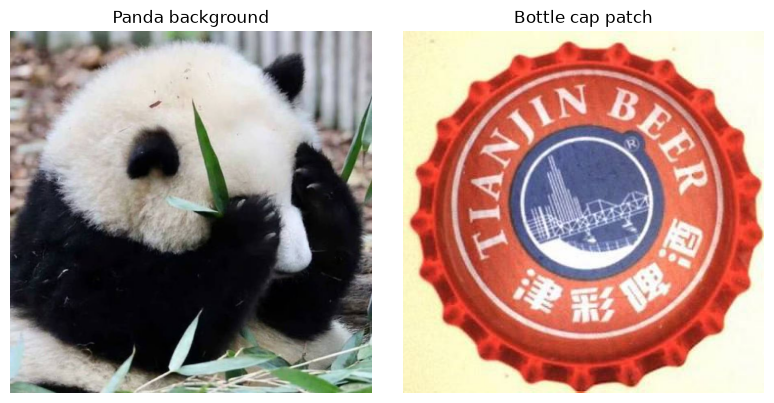

In [2]:
background = read_image(ASSETS / "user/panda.jpg")
patch = read_image(ASSETS / "pdf/bottle_cap.png")
show_images({"Panda background": background, "Bottle cap patch": patch}, cols=2)


## 3. ROI 与权重对比

在熊猫底图左下角选取一个方形 ROI，将瓶盖缩放到相同大小。alpha 表示瓶盖的权重，底图权重为 1-alpha；alpha 为 0 时保留底图，1 时完全替换该区域。观察普通加法产生的过亮现象。


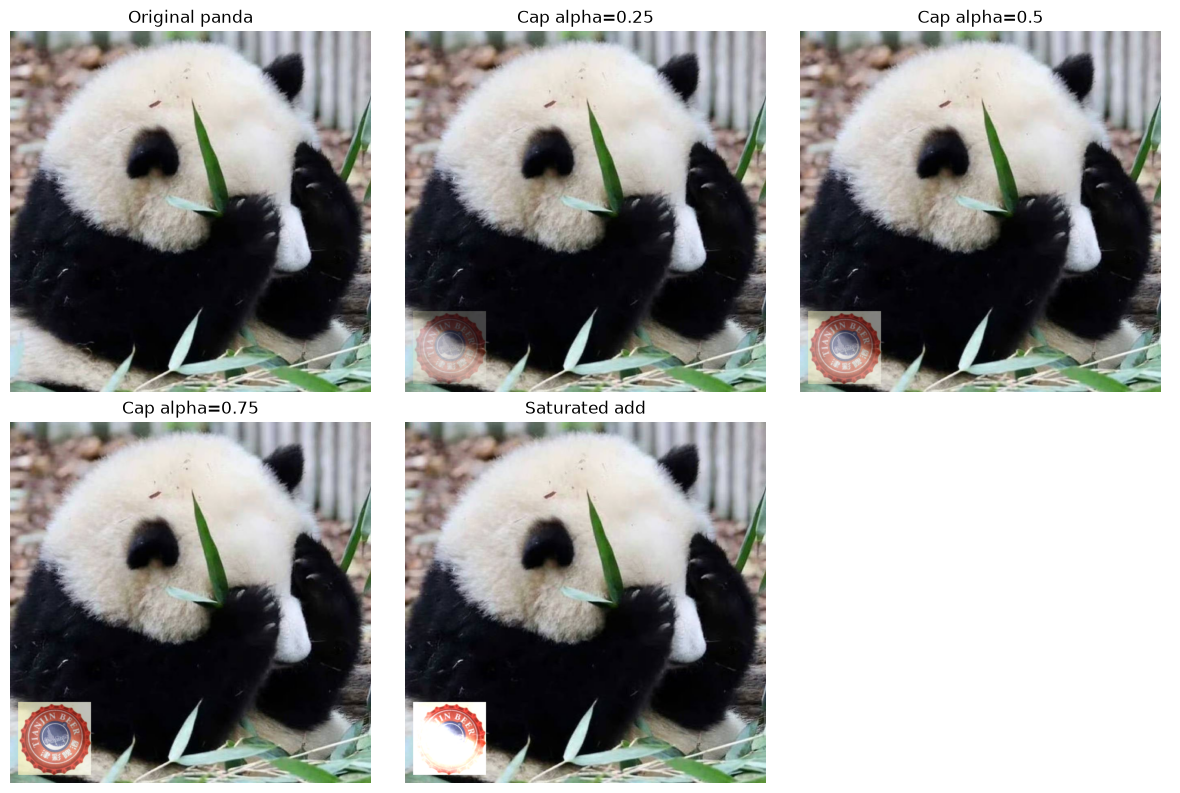

In [3]:
h, w = 180, 180
x, y = 20, background.shape[0] - h - 20
assert x >= 0 and y >= 0 and x + w <= background.shape[1] and y + h <= background.shape[0]
patch_roi = cv2.resize(patch, (w, h), interpolation=cv2.INTER_AREA)
roi = background[y:y+h, x:x+w]
results = {"Original panda": background}
for alpha in (0.25, 0.5, 0.75):
    result = background.copy()
    result[y:y+h, x:x+w] = cv2.addWeighted(roi, 1-alpha, patch_roi, alpha, 0)
    results[f"Cap alpha={alpha}"] = result
    save_image(OUT / f"blend_{alpha:.2f}.png", result)
saturated = background.copy()
saturated[y:y+h, x:x+w] = cv2.add(roi, patch_roi)
results["Saturated add"] = saturated
show_images(results, cols=3, save_to=OUT / "blend_comparison.png")


## 4. 只在一个通道融合

通道编号 0、1、2 分别表示 B、G、R。修改数组副本，避免覆盖原始底图。


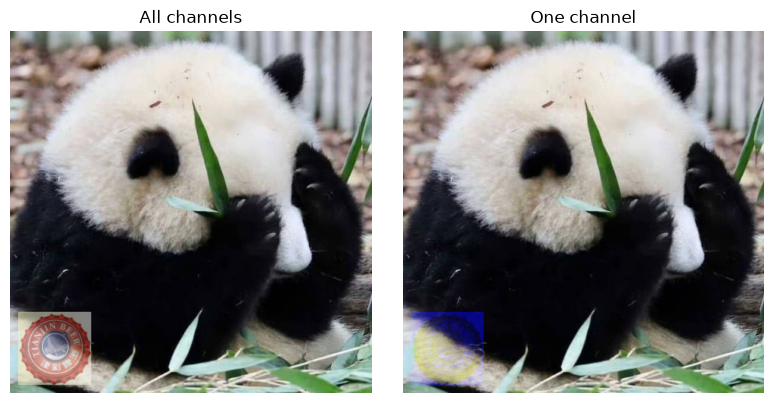

In [4]:
channels = list(cv2.split(background))
patch_gray = cv2.cvtColor(patch_roi, cv2.COLOR_BGR2GRAY)
channel_index = 0  # 练习：改为 1 或 2
channel_roi = channels[channel_index][y:y+h, x:x+w]
channels[channel_index][y:y+h, x:x+w] = cv2.addWeighted(channel_roi, 0.5, patch_gray, 0.5, 0)
channel_blend = cv2.merge(channels)
save_image(OUT / "single_channel_blend.png", channel_blend)
show_images({"All channels": results["Cap alpha=0.5"], "One channel": channel_blend}, cols=2)


## 记录与思考

1. 把 alpha 改成 0 和 1，输出分别是什么？
2. ROI 越界或两张图尺寸不一致时，应先处理哪个条件？
3. `cv2.add` 与 NumPy uint8 直接相加有什么区别？
4. 将底图换为电路板照片，保持 ROI 不越界，观察与熊猫底图融合的差别。

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab05/`；运行本 Notebook 不会改写原始素材。
